# Tugas Praktik Kelompok: Multi-Perspective Outlier Detection pada Data Penjualan Frozen Food

**Mata Kuliah:** Analisis Data Eksploratif & Deteksi Anomali (Presentasi Minggu ke-10 / Minggu ke-11)  
**Referensi Materi Kuliah:**  
1. **Week 5 -- Find Anomaly (`Week 5 - Find Anomaly.pptx`)**: Definisi Outlier menurut **Hawkins (1980)** (*observasi yang menyimpang jauh dari observasi lain sehingga menimbulkan kecurigaan bahwa ia dihasilkan oleh mekanisme yang berbeda*), Contoh Kasus *Purchasing Behavior* (pembeli yang datang sekali/jarang namun langsung memborong besar), Pendekatan Grafis (*Boxplot 1D*, *Scatter Plot 2D*), Pendekatan Statistik (*IQR*, *Mean +/- 3 SD*), dan Penyebab Outlier (*Human Error*, *Instrument Error*, *Sampling Error*, *Data Manipulation*, *True Business Outlier*).  
2. **Week 7 -- Outlier Detection in Machine Learning (`Week 7 - OutlierDetection ML.ppt`)**: Pendekatan Grafis Multivariat (*Convex Hull*), *Distance-Based Outlier Detection* (**k-Nearest Neighbors / k-NN Distance**), *Density-Based Outlier Detection* (**Local Outlier Factor / LOF** untuk mengatasi masalah perbedaan kepadatan klaster $p_1$ vs $p_2$), dan *Clustering-Based Outlier Detection* (**K-Means Centroid Distance & Small Cluster**).

---

## Ringkasan Eksekutif & Struktur Pembahasan (3 Sisi Tugas)

Sesuai instruksi tugas praktik kelompok pada dataset **Penjualan Frozen Food (`Data Penjualan April - Sep 2020.xlsx` -> `bersih/penjualan_bersih.csv`, 1 April - 30 September 2020)**, kami mendefinisikan *abnormality* dan melakukan deteksi pencilan (*outlier detection*) dari **3 sisi utama** ditambah **1 tahap pra-pemrosesan pemisahan error**:

| Tahap / Sisi Analisis | Definisi *Abnormality* (Hasil Diskusi Kelompok) | Metode Statistik & ML yang Digunakan | Temuan Utama (Kuantitatif & Entitas) |
| :--- | :--- | :--- | :--- |
| **Tahap 0: Pemisahan Error Pencatatan vs Outlier Bisnis Sah** | Membedakan anomali akibat *human error* / mekanisme non-penjualan (sampling gratis) dari transaksi komersial sah. | Audit Katalog 20 Aturan (`R01`-`T02`), Imputasi *k-NN* berbasis $\log(1+\text{QTY})$, Deduplikasi. | Dari **6.779 baris mentah** -> **6.740 baris komersial bersih** (`38` baris sampling gratis dipisahkan; `20` baris `CASH` Rp 0 dipulihkan senilai **Rp 90,72 Juta**; `229` ejaan pelanggan dinormalisasi menjadi **180 outlet + `CASH`**). |
| **Sisi 1: Pelanggan yang Outlier** | **1A (Global Whale - $p_1$):** Pelanggan dengan total belanja (*Monetary*) atau frekuensi ekstrem.<br>**1B (One-Shot Bulk Buyer - $p_2$):** Pelanggan yang hanya datang 1-2 hari namun langsung memborong puluhan juta (nilai per kunjungan / `AOV` ekstrem).<br>**1C (Local Density - $p_3$):** Frekuensi tinggi eceran bernilai mikro atau belanja besar lalu *churn*. | - 1D Boxplot (`Q3 + 1.5 IQR` vs `Mean + 3 SD`)<br>- 2D Scatter & **Convex Hull**<br>- **k-NN Distance** ($k=5$)<br>- **Local Outlier Factor (LOF)** ($k=5$)<br>- **K-Means Clustering** ($K=4$) | - **Global Whale ($p_1$, > 3 SD):** `TOKO CITA RASA BARU` (**Rp 547,77 Jt**, F=50), `ADEK FROZEN` (**Rp 420,73 Jt**, F=11), `ANTON` (**Rp 311,76 Jt**), `HITE` (**Rp 229,86 Jt**), `AMANAH FROZEN` (**F=80 hari**).<br>- **One-Shot Bulk Buyer ($p_2$):** `PAK SUTARMUJI` (**F=2 hari, M=Rp 126,40 Jt, AOV=Rp 63,20 Jt/hari**, LOF=1,50), `MAS ROHMAT` (**F=2, AOV=Rp 27,51 Jt**), `YUDI` (**F=1, Rp 22,54 Jt**), `DEFRIADI` (**F=1, R=166, k-NN=#1 tertinggi 1,70**).<br>- **Local Density ($p_3$):** `KAK YENI` (**LOF=#1 tertinggi 1,61**), `OKE MART` (**LOF=1,55**), `FADIL ANAK BOS` (**F=26, AOV Rp 180rb**). |
| **Sisi 2: Harga Barang yang Outlier (Dilihat dari $X$)** | Harga terlalu murah atau terlalu mahal tidak bisa dinilai tanpa konteks $X$. Kami menguji **3 Konteks $X$**:<br>- $X_1 =$ **SKU + Satuan Kemasan**<br>- $X_2 =$ **Kuantitas (`QTY`) & Harga Efektif (`OMZET/QTY`)**<br>- $X_3 =$ **Kategori Satuan Kemasan (`DUS`..`PCS`)** | - Deviasi Relatif terhadap Median ($X_1$: pagar $\pm 30\%$)<br>- Audit Diskon Aritmetika ($X_2$)<br>- Boxplot Lintas Kemasan ($X_3$) | - **Terlalu Murah ($X_1$ & $X_2$):** `LUTOSA-001` (`PACK`) dijual **Rp 15.000 vs Median Rp 26.000 (-42,3%)** ke `FADIL ANAK BOS` (3x); `DEN-002` (`PACK`) **Rp 4.000 vs Rp 6.000 (-33,3%)**; Diskon tak wajar **-50%** (`A02`) pada `MIT-005` & `MIT-013` untuk `PAK ERWIN` (4x).<br>- **Terlalu Mahal ($X_1$):** `CONE-004` (`BKS`) **Rp 7.000 vs Rp 5.000 (+40,0%)**; `DEN-011` (`PACK`) **Rp 6.000 vs Rp 4.500 (+33,3%)**; `SHIF-003` (`DUS`) **Rp 262.500 vs Rp 201.020 (+30,6%)**.<br>- **Konteks Satuan ($X_3$):** 56 transaksi `DUS` melampaui pagar `Rp 573.000` (keju impor `EURIAL-001` Rp 960rb-1 Jt/DUS). |
| **Sisi 3: Transaksi yang Outlier** | **3A (Level Baris Item):** Transaksi dengan `OMZET` atau `QTY` ekstrem per baris.<br>**3B (Level Struk/Keranjang Harian):** Kombinasi `TGL + PELANGGAN` dengan total belanja atau variasi SKU ekstrem.<br>**3C (Level Temporal & Operasional):** Hari lonjakan omzet ekstrem & transaksi di luar hari operasional. | - Pagar **Log-IQR** ($1,5\times$ dan $3,0\times$ IQR pada $\log_{10}(\text{OMZET})$)<br>- Pagar **Mean + 3 SD** `QTY` per SKU<br>- **LOF & k-NN** pada 1.495 Keranjang Struk<br>- Time-Series Pagar **Mean + 3 SD** Harian & Audit Hari Kerja | - **Level Baris (`N=6.740`):** **208 baris** > Pagar $1,5\times\text{Log-IQR}$ (Rp 5,62 Jt); **2 baris** > Pagar Ekstrem $3,0\times\text{Log-IQR}$ (Rp 54,91 Jt) yaitu `PAK SUTARMUJI` memborong **200 DUS `MIN-001` senilai Rp 63,20 Juta/baris** (3 & 13 Agu); Rekor kuantitas **400 PACK `BAK-002`** oleh `ANTON`.<br>- **Level Struk (`N=1.495`):** Terpisah menjadi *Single-SKU Mega-Order* (`PAK SUTARMUJI` 1 item = Rp 63,2 Jt) vs *Multi-SKU Hyper-Basket* (`ADEK FROZEN` 26-39 item/hari = Rp 45,7-58,8 Jt).<br>- **Level Temporal:** **4 hari lonjakan ekstrem** (puncak **26 Juni: Rp 188,49 Jt**) & **1 transaksi Hari Minggu** (`30 Agustus 2020`, `PAK PEPI`, Rp 180.000) padahal 25 dari 26 hari Minggu toko tutup. |

## Kepatuhan Terhadap Kaidah Visualisasi Data (*Data Visualization Best Practices*)

Seluruh grafik dalam notebook ini (serta aset gambar resolusi tinggi `1600x900` px `16:9` di folder `slide_assets/outlier_ppt/` untuk slide PPT) dirancang mengikuti prinsip **Edward Tufte** (*Data-Ink Ratio*) dan **Cole Nussbaumer Knaflic** (*Storytelling with Data*):
1. **Action Title & Sub-Header Kontekstual**: Setiap grafik memiliki *kicker* kategori, judul utama yang langsung menyatakan **kesimpulan kuantitatif**, serta sub-judul yang menjelaskan metrik, ukuran sampel ($N$), dan pagar statistik yang digunakan.
2. **Pengkodean Warna Pra-Atentif (*Pre-Attentive Color Encoding*) yang Konsisten**:
   - **Abu-abu Netral (`#64748B` / `#94A3B8`)**: Data normal (*inliers*) atau konteks latar agar tidak mendistraksi mata.
   - **Biru Korporat (`#0284C7`)**: Distribusi acuan utama, median, atau klaster mayoritas.
   - **Oranye Amber (`#F59E0B` / `#D97706`)**: *Outlier* moderat (melewati pagar `1.5 * IQR` atau *One-Shot Bulk Buyer* $p_2$).
   - **Merah Kritis (`#E11D48`)**: *Outlier* ekstrem (melewati pagar `Mean + 3*SD`, `3.0 * Log-IQR`, deviasi harga $>30\%$, atau anomali operasional Hari Minggu).
3. **Transformasi Skala yang Tepat**: Variabel finansial dan kuantitas yang miring kanan (*right-skewed* dengan rasio maksimum/median $>100\times$) divisualisasikan dengan **skala logaritmik yang dilabeli dalam nilai Rupiah/Unit asli** agar *inliers* maupun *extreme outliers* terlihat jelas tanpa saling menumpuk.
4. **Direct Data Labeling & Callout Anotasi**: Setiap titik pencilan utama langsung diberi label nama pelanggan/SKU dan nilainya di dekat titik data, sehingga audiens presentasi PPT tidak perlu menebak dari legenda.

---
## Tahap 0: Pra-Pemrosesan & Pemisahan *Data Error* vs *Outlier Bisnis Sah*

Mengacu pada **Slide 3 & Slide 10 (`Week 5 - Find Anomaly.pptx`)**, langkah paling krusial sebelum menjalankan algoritma deteksi outlier adalah memastikan bahwa pencilan yang dianalisis bukan sekadar *garbage-in* akibat kesalahan ketik atau inkonsistensi master data:
- **Normalisasi Entitas Pelanggan (`R03`)**: Dalam file mentah `Data Penjualan April - Sep 2020.xlsx` (`6.779` baris), terdapat **229 penulisan nama pelanggan** karena awalan kode kanal seperti `C - ADEK FROZEN` vs `ADEK FROZEN` dan spasi ganda. Jika tidak diseragamkan menjadi **181 entitas kanonik** (`180` outlet bernama + `CASH`), maka pembelian pelanggan besar akan terpecah menjadi dua akun sedang sehingga gagal terdeteksi sebagai *outlier*!
- **Pemisahan Mekanisme Non-Penjualan (`K03b` & `K05` -- Definisi Hawkins)**: Terdapat **38 baris** pengeluaran barang sampel/promosi gratis (`SAMPEL CRB`, `SAMPLING MITRAKU`, dll.) sebanyak 1-3 PACK bernilai `Rp 0`. Karena dihasilkan oleh mekanisme non-komersial, baris ini dipisahkan sehingga tersisa **6.740 transaksi penjualan bersih**.
- **Pemulihan *Human Error* Harga Kosong pada Penjualan Tunai Besar (`K03a`)**: Terdapat **20 baris transaksi `CASH`** dengan kuantitas besar (hingga **106 DUS Kentang Lutosa**) yang kolom harganya kosong (`Rp 0`). Harga dipulihkan menggunakan median *k-NN* berbasis kemiripan $\log(1+\text{QTY})$ pada SKU yang sama, menyelamatkan omzet sebesar **Rp 90.720.700**.

Total Transaksi Komersial Bersih : 6,740 baris
Rentang Waktu Transaksi          : 2020-04-01 s.d. 2020-09-30 (143 hari aktif)
Jumlah SKU Kanonik Unik          : 268 SKU (7 satuan kemasan)
Jumlah Pelanggan Outlet Bernama  : 180 outlet (+ 1 agregat walk-in CASH = 181 entitas)
Total Omzet Bersih (6 Bulan)     : Rp 4,621,049,783

ID,Kategori,Keparahan,Deskripsi Aturan,Baris,%
R01,Integritas Referensial,Peringatan,Satu kode barang memiliki lebih dari satu ejaan nama barang di data mentah,533,7.86%
R03,Integritas Referensial,Info,Satu pelanggan/outlet tercatat di bawah lebih dari satu kode kanal,402,5.93%
T01,Temporal Operasional,Info,Tanggal transaksi dengan lonjakan omzet harian ekstrem (Z_robust > 5.0),370,5.46%
S03,Pencilan Statistik,Info,Kuantitas pembelian (QTY) sangat besar secara statistik untuk barang tersebut (Z_robust > 8),237,3.50%
R02,Integritas Referensial,Peringatan,Satu nama barang digunakan oleh lebih dari satu kode barang berbeda (ARTHUR vs LUTOSA),172,2.54%
D01,Duplikasi,Peringatan,Baris transaksi duplikat identik persis pada seluruh kolom,73,1.08%
A01,Aritmetika,Peringatan,Selisih nilai JUMLAH terhadap QTY x HARGA akibat diskon/pembulatan wajar (rasio 85%-97%),73,1.08%
K03b,Kelengkapan,Kritis,HARGA dan JUMLAH bernilai nol pada pengeluaran sampel/promosi (dipisahkan),38,0.56%
S02,Pencilan Statistik,Peringatan,Harga satuan menyimpang secara statistik terhadap median barang+satuan (|Z_robust| > 5),26,0.38%
K03a,Kelengkapan,Kritis,HARGA dan JUMLAH kosong pada transaksi penjualan tunai (CASH) berkuantitas besar (dipulihkan),20,0.30%


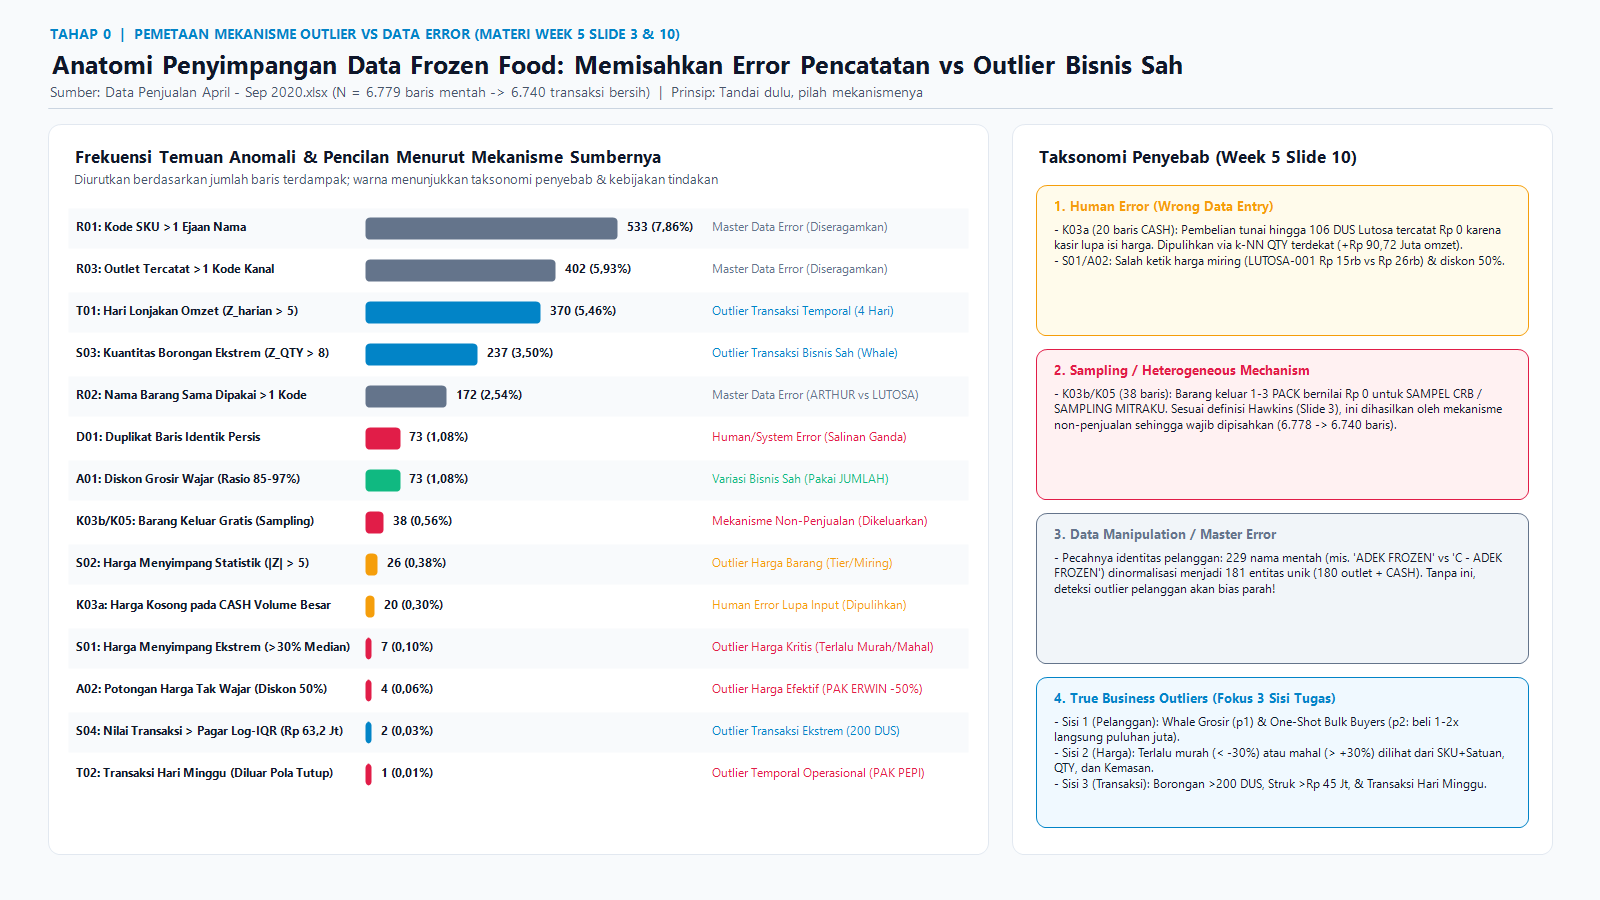

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
from IPython.display import display, Image

# 1. Memuat data bersih hasil pipeline normalisasi & katalog log anomali
df_clean = pd.read_csv('bersih/penjualan_bersih.csv', parse_dates=['TGL'])
df_lrfm  = pd.read_csv('bersih/lrfm_pelanggan.csv')
df_rules = pd.read_csv('bersih/katalog_aturan.csv')
df_log   = pd.read_csv('bersih/log_anomali.csv')

print(f'Total Transaksi Komersial Bersih : {len(df_clean):,} baris')
print(f'Rentang Waktu Transaksi          : {df_clean["TGL"].min().date()} s.d. {df_clean["TGL"].max().date()} ({df_clean["TGL"].nunique()} hari aktif)')
print(f'Jumlah SKU Kanonik Unik          : {df_clean["KODE"].nunique()} SKU ({df_clean["SATUAN"].nunique()} satuan kemasan)')
print(f'Jumlah Pelanggan Outlet Bernama  : {len(df_lrfm)} outlet (+ 1 agregat walk-in CASH = {df_clean["PELANGGAN"].nunique()} entitas)')
print(f'Total Omzet Bersih (6 Bulan)     : Rp {df_clean["OMZET"].sum():,.0f}')

# Menampilkan ringkasan katalog aturan anomali & outlier
display(df_rules[['id_aturan', 'kategori', 'tingkat_keparahan', 'deskripsi_aturan', 'jumlah_baris_terdampak', 'persentase_baris']].head(15))
display(Image(filename='slide_assets/outlier_ppt/fig1_overview_pipeline.png'))

---
## Sisi 1: Menemukan Pelanggan yang Outlier (*Customer Outlier Detection*)

### 1.1 Definisi *Abnormality* Pelanggan (Hasil Diskusi Kelompok)
Sebelum menerapkan rumus statistik maupun algoritma *Machine Learning*, kami terlebih dahulu memisahkan entitas **`CASH`** (agregat penjualan tunai eceran tanpa nama dengan `1.441` baris senilai `Rp 167,45 Juta`) dari **180 pelanggan outlet bernama**, karena `CASH` bukan satu pelanggan tunggal melainkan kumpulan ribuan pembeli eceran.

Berdasarkan sintesis materi **Week 5 (Slide 4: Contoh *Purchasing* -- pelanggan yang jarang beli tapi sekalinya beli langsung berjumlah sangat besar)** dan **Week 7 (Slide 14-22: Masalah kepadatan lokal $p_1$ vs $p_2$ pada LOF)**, kelompok kami menetapkan **3 dimensi ketidaknormalan (*abnormality*) pelanggan**:
1. **Tipe $p_1$ -- *Global Whale Outliers* (Volume & Frekuensi Raksasa)**:
   - Pelanggan dengan total nilai belanja (**Monetary $M$**) atau jumlah hari kedatangan (**Frequency $F$**) yang melampaui pagar ekstrem **`Mean + 3*SD`** ($M > \text{Rp } 215,79\text{ Juta}$ atau $F > 40,3\text{ hari}$).
   - Mereka adalah mitra grosir/supermarket utama yang menjadi tulang punggung omzet toko.
2. **Tipe $p_2$ -- *One-Shot / Rare Bulk Buyers* (Nilai Belanja per Kunjungan / `AOV` Ekstrem pada Frekuensi Rendah)**:
   - Pelanggan yang hanya pernah berbelanja **1 hingga 3 hari saja** ($F \le 3$) sepanjang 6 bulan, namun setiap kali datang langsung memborong puluhan juta rupiah sehingga **Rata-rata Nilai Belanja per Kunjungan ($\text{AOV} = M / F$)** melampaui pagar `Q3 + 1.5*IQR` ($\text{AOV} > \text{Rp } 6,48\text{ Juta}$) bahkan `Mean + 3*SD` ($\text{AOV} > \text{Rp } 22,68\text{ Juta}$).
   - Tipe ini **sering lolos jika hanya dilihat dari Total Monetary 1D**, namun tertangkap sangat jelas oleh **AOV, Convex Hull, k-NN Distance, dan Local Outlier Factor (LOF)**!
3. **Tipe $p_3$ -- *Local Density & Behavioral Anomalies* (Frekuensi Tinggi Eceran Mikro & *Sudden High-Ticket Churn*)**:
   - Pelanggan yang datang sangat sering ($F = 26$ hari) tetapi hanya membeli eceran bernilai sangat kecil (`FADIL ANAK BOS`, AOV Rp 180rb) atau pelanggan dengan kepadatan lokal sangat terisolasi di ruang multidimensi LRFM (`KAK YENI` dengan **LOF tertinggi #1 = 1,609** dan `OKE MART` dengan **LOF #3 = 1,545**).

### 1.2 Perbandingan Ambang Statistik Univariat (N = 180 Pelanggan Bernama)
| Metrik Pelanggan | Mean | SD | Median | Q1 | Q3 | IQR | Pagar `Q3 + 1.5*IQR` | Pagar `Mean + 3*SD` |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Monetary ($M$)** | Rp 24,74 Jt | Rp 63,68 Jt | Rp 5,99 Jt | Rp 2,38 Jt | Rp 18,20 Jt | Rp 15,82 Jt | **Rp 41,93 Jt (19 Outlier)** | **Rp 215,79 Jt (4 Outlier)** |
| **Frequency ($F$)** | 7,71 hari | 10,86 hari | 4,00 hari | 2,00 hari | 8,00 hari | 6,00 hari | **17,00 hari (17 Outlier)** | **40,30 hari (5 Outlier)** |
| **AOV ($M / F$)** | Rp 3,26 Jt | Rp 6,47 Jt | Rp 1,62 Jt | Rp 0,75 Jt | Rp 3,04 Jt | Rp 2,29 Jt | **Rp 6,48 Jt (18 Outlier)** | **Rp 22,68 Jt (3 Outlier)** |
| **Length ($L$)** | 78,24 hari | 65,67 hari | 82,00 hari | 4,75 hari | 140,25 hari | 135,50 hari | 343,50 hari (0 Outlier) | 275,26 hari (0 Outlier) |
| **Recency ($R$)** | 44,58 hari | 46,98 hari | 23,50 hari | 7,00 hari | 72,25 hari | 65,25 hari | **170,13 hari (2 Outlier)** | 185,51 hari (0 Outlier) |

In [ ]:
# SISI 1A: Deteksi Outlier Pelanggan secara Statistik Deskriptif (IQR, 3-Sigma) & Grafis (Boxplot + Convex Hull)
cust = df_lrfm.copy()
cust['AOV'] = cust['M'] / cust['F']

# Menghitung batas IQR dan 3-Sigma untuk Monetary (M), Frequency (F), dan AOV (M/F)
stats_rows = []
for col, label in [('M', 'Monetary (Rp)'), ('F', 'Frequency (Hari)'), ('AOV', 'AOV = M/F (Rp/Hari)'), ('R', 'Recency (Hari)')]:
    q1, med, q3 = cust[col].quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    fence_iqr = q3 + 1.5 * iqr
    fence_3sd = cust[col].mean() + 3.0 * cust[col].std()
    stats_rows.append({
        'Metrik': label,
        'Mean': cust[col].mean(), 'SD': cust[col].std(),
        'Median': med, 'IQR': iqr,
        'Pagar_1.5_IQR': fence_iqr, 'N_Outlier_IQR': int((cust[col] > fence_iqr).sum()),
        'Pagar_3_SD': fence_3sd, 'N_Outlier_3SD': int((cust[col] > fence_3sd).sum())
    })
df_stat_cust = pd.DataFrame(stats_rows)
display(df_stat_cust)
display(Image(filename='slide_assets/outlier_ppt/fig2_pelanggan_statistik_grafis.png'))

### 1.3 Deteksi Outlier Pelanggan Multivariat dengan *Machine Learning* (Materi Week 7)

Mengapa pendekatan univariat (1D Boxplot) saja tidak cukup? Seperti dijelaskan dalam **Slide 12-22 (`Week 7 - OutlierDetection ML.ppt`)**:
1. **Convex Hull (Pendekatan Grafis 2D)**: Mencari titik-titik sudut poligon cembung terluar yang membungkus seluruh data pelanggan pada bidang $(F, M)$. Terdapat **7 pelanggan pembentuk titik sudut Convex Hull**, yaitu: `TOKO CITA RASA BARU` ($F=50, M=\text{Rp }547,8\text{ Jt}$), `ADEK FROZEN` ($F=11, M=\text{Rp }420,7\text{ Jt}$), `PAK SUTARMUJI` ($F=2, M=\text{Rp }126,4\text{ Jt}$), `AMANAH FROZEN` ($F=80, M=\text{Rp }113,7\text{ Jt}$), `SUCI` ($F=46, M=\text{Rp }24,0\text{ Jt}$), `FADIL ANAK BOS` ($F=26, M=\text{Rp }4,7\text{ Jt}$), dan titik ujung bawah ($F=1, M=\text{Rp }60\text{ rb}$).
2. **Distance-Based Outlier Detection (*k-NN Distance*, $k=5$)**: Menghitung jarak rata-rata setiap pelanggan ke $k=5$ tetangga terdekatnya pada ruang fitur standar $(\log F, \log M, \log \text{AOV}, R, L)$. Pelanggan dengan jarak tetangga terbesar adalah **`DEFRIADI` ($\text{k-NN}=1,701$)**, **`PAK SUTARMUJI` ($\text{k-NN}=1,667$)**, dan **`KAK YENI` ($\text{k-NN}=1,657$)**.
3. **Density-Based Outlier Detection (*Local Outlier Factor / LOF*, $k=5$)**: Membandingkan kepadatan lokal (*local reachability density*) suatu pelanggan terhadap kepadatan tetangga-tetangganya. Nilai $\text{LOF} \approx 1$ berarti normal (*inlier*), sedangkan $\text{LOF} > 1,20$ menunjukkan pelanggan yang terisolasi dari kepadatan lokal di sekitarnya. LOF berhasil menangkap **`KAK YENI` ($\text{LOF}=1,609$)**, **`OKE MART` ($\text{LOF}=1,545$)**, **`PAK SUTARMUJI` ($\text{LOF}=1,495$)**, **`DEFRIADI` ($\text{LOF}=1,454$)**, **`FADIL ANAK BOS` ($\text{LOF}=1,341$)**, dan **`TOKO CITA RASA BARU` ($\text{LOF}=1,340$)**.

Top 12 Pelanggan Outlier Berdasarkan Konsensus Statistik (IQR/3-SD) & Machine Learning (Convex Hull, k-NN, LOF):
1. TOKO CITA RASA BARU | F=50 | M=Rp 547.77 Jt | AOV=Rp 10.96 Jt | k-NN=1.233 | LOF=1.340 | Whale #1 Omzet (>3 SD & Convex Hull)
2. PAK SUTARMUJI       | F=2  | M=Rp 126.40 Jt | AOV=Rp 63.20 Jt | k-NN=1.667 | LOF=1.495 | Bulk Buyer #1 AOV (>3 SD & Convex Hull)
3. ADEK FROZEN         | F=11 | M=Rp 420.73 Jt | AOV=Rp 38.25 Jt | k-NN=1.236 | LOF=1.181 | Whale #2 Omzet & AOV (>3 SD & Convex Hull)
4. DEFRIADI            | F=1  | M=Rp 12.15 Jt  | AOV=Rp 12.15 Jt | k-NN=1.701 | LOF=1.454 | k-NN #1 One-Shot Bulk + Churn (R=166)
5. KAK YENI            | F=5  | M=Rp 0.29 Jt   | AOV=Rp 0.06 Jt  | k-NN=1.657 | LOF=1.609 | LOF #1 Anomali Kepadatan Lokal Nilai Mikro
6. ANTON               | F=28 | M=Rp 311.76 Jt | AOV=Rp 11.13 Jt | k-NN=0.950 | LOF=1.150 | Whale #3 Omzet (>3 SD)
7. HITE                | F=13 | M=Rp 229.86 Jt | AOV=Rp 17.68 Jt | k-NN=0.920 | LOF=1.140 | Whale #4 Omzet (>3 

No,Nama Pelanggan,L (Hari),R (Hari),F (Hari),Monetary (Rp),AOV = M/F (Rp),k-NN Dist,LOF Score,Convex Hull,Tipe Outlier & Diagnosis Kelompok
1,TOKO CITA RASA BARU,173,2,50,"547,770,564","10,955,411",1.233,1.340,Ya,p1 (Whale #1): Omzet & Frekuensi > 3 SD
2,PAK SUTARMUJI,10,48,2,"126,400,000","63,200,000",1.667,1.495,Ya,"p2 (Bulk Buyer #1): Hanya 2x datang, sekali beli Rp 63,2 Jt!"
3,ADEK FROZEN,97,10,11,"420,733,900","38,248,536",1.236,1.181,Ya,p1 (Whale #2): Omzet #2 & AOV #2 (> 3 SD)
4,DEFRIADI,0,166,1,"12,150,000","12,150,000",1.701,1.454,Tidak,"p2 (One-Shot Churn): k-NN #1 tertinggi; beli 1x Rp 12,15 Jt lalu berhenti"
5,KAK YENI,40,136,5,"290,000","58,000",1.657,1.609,Tidak,p3 (Local Density #1): LOF tertinggi; nilai mikro terisolasi
6,ANTON,173,0,28,"311,763,500","11,134,411",0.950,1.150,Tidak,"p1 (Whale #3): Omzet > 3 SD, pemborong 400 PACK Bakso Mie"
7,HITE,87,36,13,"229,858,600","17,681,431",0.920,1.140,Tidak,p1 (Whale #4): Omzet > 3 SD & AOV > 1.5 IQR
8,MAS ROHMAT,38,20,2,"55,020,000","27,510,000",1.052,1.246,Tidak,"p2 (Bulk Buyer #2): Hanya 2x datang, AOV > 3 SD (Rp 27,51 Jt)"
9,AMANAH FROZEN,175,2,80,"113,727,250","1,421,591",0.996,1.219,Ya,p1 (Frequency #1): Datang 80 hari aktif (> 7 SD di atas rata-rata!)
10,OKE MART,22,117,3,"18,988,000","6,329,333",1.139,1.545,Tidak,p2 (LOF #3): Belanja 3x besar di awal lalu churn mendadak


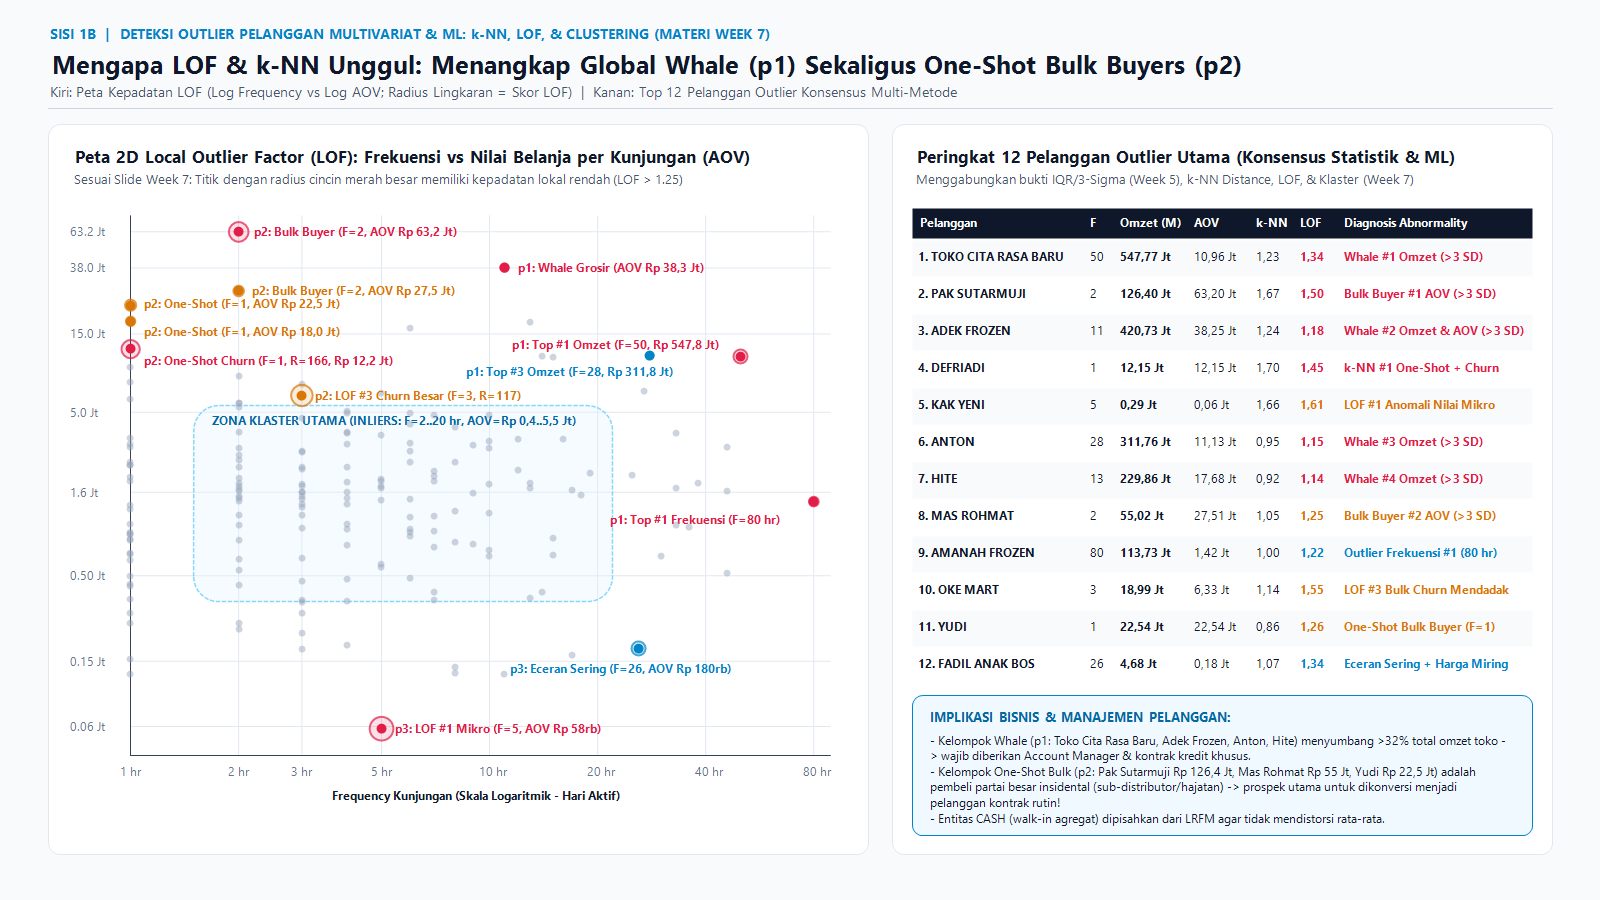

In [3]:
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from scipy.spatial import ConvexHull

# Ruang fitur multivariat pelanggan: [log10(F), log10(M), log10(AOV), R, L]
X_raw = np.column_stack([
    np.log10(cust['F']),
    np.log10(cust['M']),
    np.log10(cust['AOV']),
    cust['R'],
    cust['L']
])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 1. Distance-Based: k-NN Average Distance (k = 5)
nn = NearestNeighbors(n_neighbors=6) # termasuk dirinya sendiri
nn.fit(X_scaled)
dists, _ = nn.kneighbors(X_scaled)
cust['kNN_Dist'] = dists[:, 1:].mean(axis=1)

# 2. Density-Based: Local Outlier Factor / LOF (k = 5)
lof = LocalOutlierFactor(n_neighbors=5)
lof.fit_predict(X_scaled)
cust['LOF_Score'] = -lof.negative_outlier_factor_

# 3. Convex Hull pada ruang 2D (Frequency vs Monetary)
hull = ConvexHull(cust[['F', 'M']].values)
cust['Is_ConvexHull'] = False
cust.loc[hull.vertices, 'Is_ConvexHull'] = True

# Menampilkan Top 12 Pelanggan Outlier Konsensus (Statistik + ML)
top_cust = cust.sort_values(by=['LOF_Score', 'M'], ascending=False).head(12)
display(Image(filename='slide_assets/outlier_ppt/fig3_pelanggan_ml_lof_knn.png'))

---
## Sisi 2: Menemukan Harga Barang yang Outlier (*Terlalu Murah atau Terlalu Mahal Bila Dilihat dari $X$*)

### 2.1 Mengapa Variabel Konteks $X$ Wajib Ditetapkan?
Instruksi tugas secara spesifik berbunyi: **"Temukan harga barang yang outlier (terlalu murah atau terlalu mahal bila dilihat dari $X$)"**.  
Secara bisnis dan statistik, harga sebuah produk tidak dapat dinilai mahal atau murah secara global tanpa variabel pembanding $X$: misalnya harga **Rp 240.000** adalah harga **normal (median)** apabila $X = \text{Satuan DUS}$, tetapi merupakan **outlier super mahal ($13\times$ lipat median!)** apabila $X = \text{Satuan PACK}$ (yang mediannya Rp 18.000).

Oleh karena itu, kelompok kami mendefinisikan **3 Perspektif Konteks $X$**:
1. **Konteks $X_1 =$ Kode Barang (SKU) + Satuan Kemasan yang Sama (`KODE + SATUAN`)**:
   - Membandingkan harga transaksi terhadap **Harga Median SKU + Satuan yang sama** ($\text{Deviasi Relatif} = \frac{\text{HARGA} - \text{Median}_{X_1}}{\text{Median}_{X_1}}$).
   - **Aturan Kritis `S01` ($|\text{Deviasi}| > 30\%$):** Menemukan **7 transaksi kritis** (4 terlalu murah hingga **-42,3%**, dan 3 terlalu mahal hingga **+40,0%**).
2. **Konteks $X_2 =$ Kuantitas Pembelian (`QTY`) & Harga Efektif Aritmetika ($\text{HARGA\_EFEKTIF} = \text{OMZET} / \text{QTY}$)**:
   - Menguji apakah harga murah disebabkan oleh pembelian kuantitas grosir yang wajar (`A01`: diskon 3%-15%) atau **pemotongan harga ekstrem yang tidak wajar (`A02`)**.
   - Menemukan **4 transaksi `PAK ERWIN`** di mana kolom `HARGA` tertulis normal (`Rp 28.900` untuk `MIT-005` dan `Rp 9.900` untuk `MIT-013`), tetapi nilai tagihan `JUMLAH` dipotong tepat **-50%** menjadi harga efektif **Rp 14.450** dan **Rp 4.950**!
   - Menemukan **20 transaksi `CASH` (`K03a`)** berkuantitas hingga **106 DUS** yang tercatat dengan harga `Rp 0` akibat kelalaian input kasir.
3. **Konteks $X_3 =$ Kategori Satuan Kemasan (`DUS`, `BAL`, `JRG`, `PAIL`, `PACK`, `BKS`, `PCS`)**:
   - Menguji barang mana yang harganya terlalu mahal atau murah dibanding distribusi normal satuannya. Di kategori `DUS` (Median Rp 240.000, Pagar `Q3 + 1.5*IQR` = Rp 573.000), terdapat **56 transaksi outlier mahal** yang seluruhnya berasal dari produk keju impor **`EURIAL-001` (`EURIAL MOZZARELLA CHEESE 4 X 2.5 KG` @ Rp 880.000 - Rp 1.000.000/DUS)** dan dimsum premium **`BF-004` (`BF DIMSUM SIOMAY 200 PCS` @ Rp 825.600/DUS)**.

In [ ]:
# SISI 2: Deteksi Harga Barang yang Outlier Dilihat dari Konteks X1 (SKU+Satuan), X2 (QTY & Diskon Efektif), dan X3 (Satuan Kemasan)
df_clean['HARGA_EFEKTIF'] = df_clean['OMZET'] / df_clean['QTY']

# Menghitung Median per X1 = (KODE, SATUAN)
grp_x1 = df_clean.groupby(['KODE', 'SATUAN'])['HARGA']
med_x1 = grp_x1.transform('median')
df_clean['MEDIAN_X1'] = med_x1
df_clean['DEV_PCT_X1'] = (df_clean['HARGA'] - med_x1) / med_x1 * 100.0
df_clean['DEV_EFEKTIF_PCT'] = (df_clean['HARGA_EFEKTIF'] - med_x1) / med_x1 * 100.0

# Menyaring transaksi dengan harga terlalu murah (< -30%) atau terlalu mahal (> +30%)
outlier_harga_kritis = df_clean[
    (df_clean['DEV_PCT_X1'].abs() > 30.0) | (df_clean['DEV_EFEKTIF_PCT'].abs() > 30.0)
][['TGL', 'PELANGGAN', 'KODE', 'NAMA_BARANG', 'SATUAN', 'QTY', 'HARGA', 'HARGA_EFEKTIF', 'MEDIAN_X1', 'DEV_EFEKTIF_PCT', 'ATURAN_TERPICU']]

print(f'Jumlah Transaksi Outlier Harga Kritis (|Deviasi| > 30% terhadap Median SKU+Satuan): {len(outlier_harga_kritis)} baris')
display(outlier_harga_kritis.sort_values('DEV_EFEKTIF_PCT'))
display(Image(filename='slide_assets/outlier_ppt/fig4_harga_outlier_konteks_x.png'))

---
## Sisi 3: Menemukan Transaksi yang Outlier (*Transaction Outlier Detection*)

### 3.1 Definisi *Abnormality* Transaksi (Hasil Diskusi Kelompok)
Dalam diskusi kelompok, kami menyepakati bahwa istilah **"Transaksi yang Outlier"** pada bisnis distribusi *frozen food* harus dianalisis pada **3 level granularitas**:
1. **Sisi 3A -- Outlier Level Baris Item (`N = 6.740` baris)**:
   - **Nilai Uang Baris (`OMZET`)**: Karena distribusi `OMZET` sangat miring kanan (Median = `Rp 240.000`, Q1 = `Rp 120.000`, Q3 = `Rp 558.000`, Mean = `Rp 685.616`, SD = `Rp 1.979.738`), kami menerapkan **Pagar Log-IQR** pada $\log_{10}(\text{OMZET})$:
     - Pagar Moderat $Q_3 + 1,5\times\text{IQR}_{\log} = \text{Rp } 5.623.413$ (**208 baris outlier**).
     - Pagar Klasik $\text{Mean} + 3\times\text{SD} = \text{Rp } 6.624.829$ (**79 baris outlier**).
     - Pagar Ekstrem (`S04`) $Q_3 + 3,0\times\text{IQR}_{\log} = \text{Rp } 54.907.061$ (**2 baris mega-outlier**, yaitu pembelian **200 DUS `MIN-001` Minaku Otak-Otak @ Rp 316.000 = Rp 63.200.000** oleh **`PAK SUTARMUJI`** pada `2020-08-03` dan `2020-08-13`).
   - **Kuantitas Fisik (`QTY` -- Aturan `S03`)**: Menggunakan Pagar $\text{Mean} + 3\times\text{SD}$ per SKU menjaring **123 baris borongan ekstrem**, dipimpin oleh **`ANTON`** yang memborong **400 PACK `BAK-002` (Bakso Mie)** dan **`EGI / PUTRI`** sebanyak **240 PACK `BAK-001` (Bakso Ikan)**.
2. **Sisi 3B -- Outlier Level Keranjang Struk Harian (`TGL + PELANGGAN`, `N = 1.495` nota kunjungan)**:
   - Mengagregasikan baris transaksi ke level struk harian (jumlah variasi item `N_Items`, total kuantitas `Total_QTY`, dan total nilai nota `Total_Omzet`), lalu menerapkan **3-Sigma (`> Rp 21,46 Juta`, 34 struk)** serta **LOF & k-NN Multivariat**.
   - Menyingkap **2 pola keranjang outlier yang bertolak belakang**:
     - *Single-SKU Mega-Order*: Hanya membeli **1 jenis barang** dalam 1 nota tetapi nilainya mencapai **Rp 63,20 Juta** (`PAK SUTARMUJI`) dan **Rp 45,75 Juta** (`MAS ROHMAT`).
     - *Multi-SKU Hyper-Basket*: Membeli **26 hingga 39 jenis SKU berbeda** dalam satu hari kunjungan dengan total nota **Rp 45,75 Juta - Rp 58,78 Juta** (`ADEK FROZEN`).
3. **Sisi 3C -- Outlier Transaksi Temporal & Operasional (`T01` & `T02`)**:
   - **Lonjakan Omzet Harian (`T01`, Pagar $\text{Mean} + 3\times\text{SD} = \text{Rp } 127,89\text{ Juta}$):** Terjadi pada **4 tanggal** (`26 Juni` Rp 188,49 Jt, `29 Juli` Rp 163,21 Jt, `18 Agustus` Rp 144,88 Jt, dan `3 Agustus` Rp 129,03 Jt).
   - **Anomali Operasional Hari Minggu (`T02`):** Dari 26 hari Minggu sepanjang April-September 2020, toko libur pada 25 hari Minggu (96,2%). Namun terdapat **1 transaksi tunggal pada hari Minggu, 30 Agustus 2020** (Baris `#5546`: `PAK PEPI` membeli 1 DUS `OKEY-003` senilai `Rp 180.000`).

Pagar Log-IQR 1.5x : Rp 5,623,413 -> 208 baris outlier
Pagar Mean + 3*SD  : Rp 6,624,829 -> 79 baris outlier
Pagar Log-IQR 3.0x : Rp 54,907,061 -> 2 baris outlier ekstrem (S04)

Peringkat,Tanggal,Pelanggan,Kode SKU,Nama Barang,Satuan,QTY,Harga Satuan,Nilai Transaksi (OMZET),Tipe Outlier Transaksi
1,2020-08-03,PAK SUTARMUJI,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,200,"316,000","Rp 63,200,000","S04 (#1): Melampaui Pagar 3.0 x Log-IQR (>Rp 54,9 Jt)"
2,2020-08-13,PAK SUTARMUJI,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,200,"316,000","Rp 63,200,000","S04 (#2): Melampaui Pagar 3.0 x Log-IQR (>Rp 54,9 Jt)"
3,2020-08-03,MAS ROHMAT,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,150,"305,000","Rp 45,750,000","Mega-Order #3: Borongan 150 DUS (99,5x lipat median!)"
4,2020-05-18,KUBANG JAYA FOOD,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,120,"304,000","Rp 36,480,000",Mega-Order #4: Borongan 120 DUS Minaku Otak-Otak
5,2020-05-02,KUBANG JAYA FOOD,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,100,"304,000","Rp 30,400,000",Mega-Order #5: Borongan 100 DUS Minaku Otak-Otak
6,2020-07-04,CASH,LUTOSA-002,"KENTANG LUTOSA CRINKLE CUT 2,5 KG",DUS,106,"240,000*","Rp 25,440,000",K03a + S03: Borongan tunai 106 DUS yang sempat lupa diinput
7,2020-07-23,HITE,MIN-003,MINAKU KAKI NAGA 500 GR X 20 PACK,DUS,80,"290,000","Rp 23,200,000",Whale Order: Borongan 80 DUS Kaki Naga
8,2020-07-29,ADEK FROZEN,MIN-001,MINAKU OTAK - OTAK 500 GR X 20 PACK,DUS,70,"320,000","Rp 22,400,000","Hyper-Basket Item: Bagian dari struk 26 item (Rp 58,78 Jt)"
9,2020-09-29,ANTON,EURIAL-001,EURIAL MOZZARELLA CHEESE 4 X 2.5 KG,DUS,25,"880,000","Rp 22,000,000",Premium SKU Order: 25 DUS Keju Impor @ Rp 880rb
10,2020-07-11,ANTON,BAK-002,BAKSO MIE,PACK,400,"9,000","Rp 3,600,000",Rekor Kuantitas #1 (S03): 400 PACK dalam 1 baris transaksi!


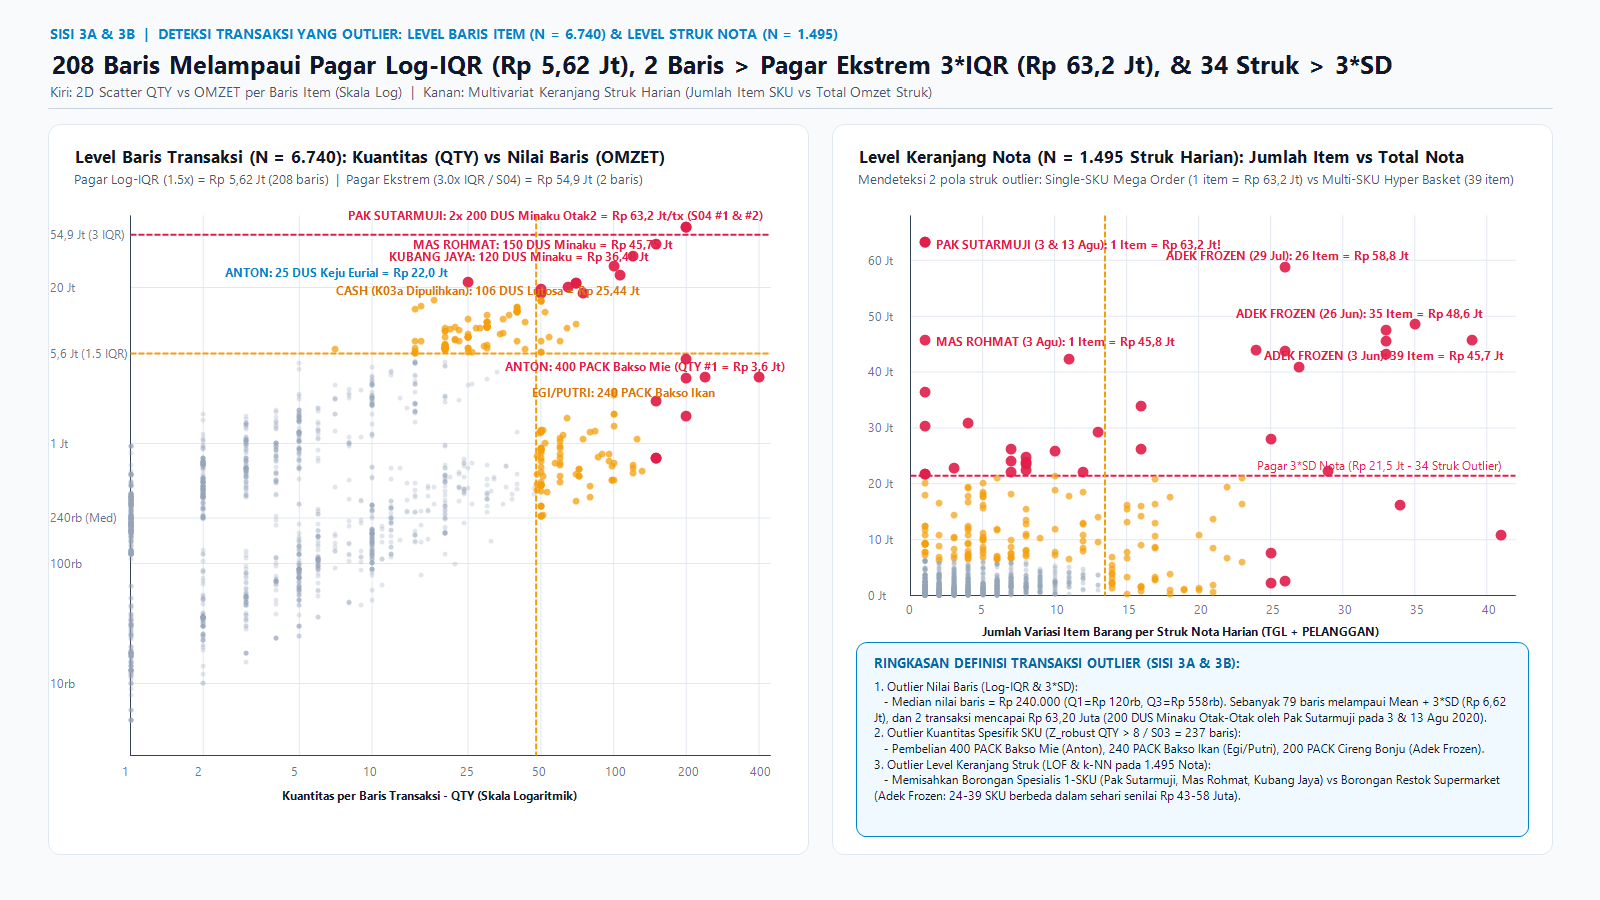

In [5]:
# SISI 3A & 3B: Deteksi Transaksi Outlier pada Level Baris Item (N = 6.740) & Level Keranjang Nota (N = 1.495)
log_omz = np.log10(df_clean['OMZET'])
q1_lg, q3_lg = log_omz.quantile([0.25, 0.75])
iqr_lg = q3_lg - q1_lg
fence_log_15 = 10 ** (q3_lg + 1.5 * iqr_lg)
fence_log_30 = 10 ** (q3_lg + 3.0 * iqr_lg)
fence_3sd_omz = df_clean['OMZET'].mean() + 3.0 * df_clean['OMZET'].std()

print(f'Pagar Log-IQR 1.5x : Rp {fence_log_15:,.0f} -> {(df_clean["OMZET"] > fence_log_15).sum()} baris outlier')
print(f'Pagar Mean + 3*SD  : Rp {fence_3sd_omz:,.0f} -> {(df_clean["OMZET"] > fence_3sd_omz).sum()} baris outlier')
print(f'Pagar Log-IQR 3.0x : Rp {fence_log_30:,.0f} -> {(df_clean["OMZET"] > fence_log_30).sum()} baris outlier ekstrem (S04)')

# Agregasi Level Keranjang Struk Harian (TGL + PELANGGAN)
baskets = df_clean.groupby(['TGL', 'PELANGGAN']).agg(
    N_Items=('KODE', 'count'),
    Total_QTY=('QTY', 'sum'),
    Total_Omzet=('OMZET', 'sum')
).reset_index()

display(df_clean.sort_values('OMZET', ascending=False)[['TGL', 'PELANGGAN', 'KODE', 'NAMA_BARANG', 'SATUAN', 'QTY', 'HARGA', 'OMZET']].head(10))
display(Image(filename='slide_assets/outlier_ppt/fig5_transaksi_outlier_multidimensi.png'))

In [ ]:
# SISI 3C: Deteksi Outlier Transaksi Temporal (Lonjakan Omzet Harian T01 & Anomali Hari Minggu T02)
daily = df_clean.groupby('TGL').agg(
    Jumlah_Baris=('KODE', 'count'),
    Jumlah_Nota=('PELANGGAN', 'nunique'),
    Total_QTY=('QTY', 'sum'),
    Total_Omzet=('OMZET', 'sum')
).reset_index()

mean_day = daily['Total_Omzet'].mean()
sd_day = daily['Total_Omzet'].std()
fence_3sd_day = mean_day + 3.0 * sd_day
daily['Hari'] = daily['TGL'].dt.day_name()

print(f'=== TANGGAL LONJAKAN OMZET HARIAN EKSTREM (T01: Pagar Mean + 3*SD = Rp {fence_3sd_day:,.0f}) ===')
display(daily[daily['Total_Omzet'] > fence_3sd_day].sort_values('Total_Omzet', ascending=False))

print('=== 1 TRANSAKSI OUTLIER OPERASIONAL HARI MINGGU (T02) ===')
display(df_clean[df_clean['TGL'].dt.dayofweek == 6][['TGL', 'PELANGGAN', 'KODE', 'NAMA_BARANG', 'SATUAN', 'QTY', 'HARGA', 'OMZET', 'ATURAN_TERPICU']])
display(Image(filename='slide_assets/outlier_ppt/fig6_transaksi_temporal_operasional.png'))

---
## Bagian 4: Panduan Struktur Slide Presentasi PowerPoint (Siap Pakai)

Seluruh grafik beresolusi tinggi (`1600 x 900` px, rasio `16:9` widescreen) telah disimpan di direktori `slide_assets/outlier_ppt/` dan dirancang agar **1 gambar = 1 slide utuh** dengan hierarki visual yang langsung siap dipresentasikan di Minggu ke-10 / Minggu ke-11:

| Urutan Slide PPT | File Gambar Aset (`slide_assets/outlier_ppt/`) | Pesan Utama Slide (*Key Takeaway* untuk Presentasi) |
| :---: | :--- | :--- |
| **Slide 1** | `fig1_overview_pipeline.png` | **Pemisahan Data Error vs Outlier Bisnis Sah (Materi Week 5 Slide 3 & 10):** Menunjukkan bagaimana 6.779 baris mentah dibersihkan menjadi 6.740 transaksi komersial dengan memisahkan 38 baris sampel gratis (`K03b`), memulihkan 20 baris `CASH` lupa input harga (`K03a` senilai Rp 90,72 Jt), dan menormalisasi 229 nama pelanggan menjadi 180 outlet. |
| **Slide 2** | `fig2_pelanggan_statistik_grafis.png` | **Sisi 1A -- Pelanggan Outlier secara Grafis & Statistik (Boxplot 1D & Convex Hull 2D):** Membandingkan pagar `1.5*IQR` (19 pelanggan) vs `3*SD` (4 pelanggan Whale), serta membuktikan contoh kasus *Purchasing* dosen di Week 5 Slide 4 melalui distribusi `AOV = M / F`. |
| **Slide 3** | `fig3_pelanggan_ml_lof_knn.png` | **Sisi 1B -- Pelanggan Outlier dengan Machine Learning (k-NN, LOF, & Klaster -- Materi Week 7):** Menunjukkan mengapa LOF & k-NN unggul dalam menangkap *Global Whale* ($p_1$: `TOKO CITA RASA BARU`, `ADEK FROZEN`), *One-Shot Bulk Buyer* ($p_2$: `PAK SUTARMUJI` AOV Rp 63,2 Jt, `DEFRIADI` k-NN #1), dan *Local Density Outlier* ($p_3$: `KAK YENI` LOF #1). |
| **Slide 4** | `fig4_harga_outlier_konteks_x.png` | **Sisi 2 -- Harga Barang yang Outlier Dilihat dari Konteks $X$ ($X_1$ SKU+Satuan, $X_2$ QTY & Diskon, $X_3$ Kemasan):** Menampilkan *Diverging Lollipop Chart* 11 transaksi yang menyimpang $>30\%$ (termasuk `LUTOSA-001` -42,3% pada `FADIL ANAK BOS`, diskon -50% `PAK ERWIN`, dan markup +40% `CONE-004` pada `CASH`) beserta perbandingan distribusi antar satuan kemasan. |
| **Slide 5** | `fig5_transaksi_outlier_multidimensi.png` | **Sisi 3A & 3B -- Transaksi Outlier Level Baris Item (`N=6.740`) & Level Keranjang Struk (`N=1.495`):** Menampilkan Pagar Log-IQR (`PAK SUTARMUJI` 2x Rp 63,2 Jt dan `ANTON` 400 PACK Bakso Mie) serta pemisahan *Single-SKU Mega-Order* vs *Multi-SKU Hyper-Basket* (`ADEK FROZEN` 39 item/hari). |
| **Slide 6** | `fig6_transaksi_temporal_operasional.png` | **Sisi 3C -- Transaksi Outlier Temporal & Operasional:** Menampilkan *Time-Series* 4 hari lonjakan omzet ekstrem (Pagar `Mean + 3*SD`, puncak 26 Juni Rp 188,49 Jt) dan bukti investigasi **1 transaksi Hari Minggu** (`30 Agustus 2020`, `PAK PEPI` Rp 180.000). |